In [15]:
import os
import io
import time
import json
import requests
import numpy as np
import pandas as pd
from PIL import Image
from concurrent.futures import ThreadPoolExecutor, as_completed

import ee
from kaggle_secrets import UserSecretsClient

import torch
import torchvision.models as models

import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
import shap
import warnings
warnings.filterwarnings("ignore")

# ==============================================================================
# STEP 1: INITIALIZE GOOGLE EARTH ENGINE & MOBILENETV2
# ==============================================================================
print("[STEP 1/5] Initializing GEE and MobileNetV2...")

try:
    user_secrets = UserSecretsClient()
    secret_value = user_secrets.get_secret("API_KEY")
    key_dict = json.loads(secret_value)
    credentials = ee.ServiceAccountCredentials(
        key_dict['client_email'], key_data=secret_value
    )
    ee.Initialize(credentials=credentials)
    print("   └─ ✅ GEE Authenticated via Service Account!")
except Exception as e:
    print(f"   └─ ⚠️ Service Account authentication failed ({e}). Falling back...")
    ee.Initialize()

os.makedirs("logs", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("ground_truth_images", exist_ok=True)

# MobileNetV2 Backbone for 1280-dim spatial vector
mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
spatial_encoder = torch.nn.Sequential(*list(mobilenet.children())[:-1])
spatial_encoder.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
spatial_encoder.to(device)
print(f"   └─ ✅ MobileNetV2 loaded on device: {device}")

# ==============================================================================
# STEP 2: LOAD DATASET & ASSIGN UNIQUE ROW KEYS
# ==============================================================================
print("\n[STEP 2/5] Loading master features dataset...")
csv_path = '/kaggle/input/datasets/grandvizard/features/master_features_dataset.csv'
if not os.path.exists(csv_path):
    csv_path = 'master_features_dataset.csv'

df = pd.read_csv(csv_path)

# Filter for validated GOOD samples and create a guaranteed unique key
df_valid = df[df['Quality'] == 'GOOD'].copy().reset_index(drop=True)
df_valid['Unique_Key'] = df_valid.index.astype(str)

print(f"   └─ Total Valid Samples to Extract: {len(df_valid)}")

# ==============================================================================
# STEP 3: MULTI-THREADED GEE SPATIAL EXTRACTION
# ==============================================================================
def get_mobilenet_spatial_vector(row):
    unique_key = str(row['Unique_Key'])
    lat = float(row['Latitude'])
    lon = float(row['Longitude'])
    s_date = str(row['Sentinel_Date']).split("T")[0].strip()

    try:
        point = ee.Geometry.Point([lon, lat])
        target_date = ee.Date(s_date)
        start_date = target_date.advance(-20, 'day')
        end_date = target_date.advance(20, 'day')

        def mask_s2_clouds(img):
            scl = img.select('SCL')
            mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
            return img.updateMask(mask)

        # Sentinel-2 Harmonized Collection
        collection = (
            ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterBounds(point)
            .filterDate(start_date, end_date)
            .map(mask_s2_clouds)
            .select(['B12', 'B8', 'B4'])
        )

        # Build visualization (B12: SWIR, B8: NIR, B4: Red)
        img = collection.median().visualize(bands=['B12', 'B8', 'B4'], min=0, max=4000)

        # Compute client-side bounding box (~2240m buffer)
        delta_lat = 1120.0 / 111320.0
        delta_lon = 1120.0 / (111320.0 * np.cos(np.radians(lat)))
        bbox = [lon - delta_lon, lat - delta_lat, lon + delta_lon, lat + delta_lat]

        url = img.getThumbURL({
            'region': bbox,
            'dimensions': '224x224',
            'format': 'png'
        })

        resp = requests.get(url, timeout=20)
        if resp.status_code != 200:
            return unique_key, None, f"HTTP Error {resp.status_code}"

        pil_img = Image.open(io.BytesIO(resp.content)).convert('RGB')

        # Save Ground Truth Image Patch
        img_save_path = os.path.join('ground_truth_images', f"patch_{unique_key}.png")
        pil_img.save(img_save_path)

        # PyTorch Feature Extraction
        np_img = np.array(pil_img, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(np.transpose(np_img, (2, 0, 1))).unsqueeze(0).to(device)

        with torch.no_grad():
            features = spatial_encoder(tensor)
            pooled = torch.nn.functional.adaptive_avg_pool2d(features, (1, 1))
            vector_1280 = pooled.flatten().cpu().numpy()

        return unique_key, vector_1280, 'SUCCESS'

    except Exception as e:
        return unique_key, None, f"ERROR: {str(e)}"

print("\n[STEP 3/5] Extracting spatial embeddings & saving ground truth patches...")
start_time = time.time()

vector_dict = {}
failures = []
MAX_WORKERS = 8

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = {
        executor.submit(get_mobilenet_spatial_vector, row): row
        for _, row in df_valid.iterrows()
    }

    for completed, future in enumerate(as_completed(futures), 1):
        ukey, vector, status = future.result()

        if status == 'SUCCESS' and vector is not None:
            vector_dict[ukey] = vector
        else:
            failures.append({'Unique_Key': ukey, 'Error': status})

        if completed % 200 == 0 or completed == len(df_valid):
            print(f"   ├─ Progress: {completed}/{len(df_valid)} processed | Valid Extracted: {len(vector_dict)}")

if failures:
    pd.DataFrame(failures).to_csv('logs/spatial_extraction_failures.csv', index=False)
    print(f"   └─ ⚠️ Logged {len(failures)} failures to logs/spatial_extraction_failures.csv")

# ==============================================================================
# STEP 4: MULTIMODAL FEATURE ENGINEERING & MATRIX PERSISTENCE
# ==============================================================================
print("\n[STEP 4/5] Aligning data, engineering environmental indices...")

# Filter DataFrame to successfully extracted keys
successful_keys = list(vector_dict.keys())
df_final = df_valid[df_valid['Unique_Key'].isin(successful_keys)].copy()

# Raw Environmental Features
env_cols_raw = [
    'Temp', 'Humidity', 'Wind', 'Rainfall', 'Pressure',
    'SolarRad', 'WindDir', 'DewPoint', 'Elevation', 'LandCover_ID'
]

# Ensure missing columns (e.g., Elevation/LandCover_ID) are safely initialized if missing
for col in env_cols_raw:
    if col not in df_final.columns:
        df_final[col] = 0.0

X_env_raw = df_final[env_cols_raw].fillna(0).values

# Derived environmental indicators
temp = X_env_raw[:, 0]
rh = np.clip(X_env_raw[:, 1], 1e-4, 100.0)
wind = X_env_raw[:, 2]

es = 0.61078 * np.exp((17.27 * temp) / (temp + 237.3))
ea = es * (rh / 100.0)
vpd = (es - ea).reshape(-1, 1)
hdw = (wind * (es - ea)).reshape(-1, 1)

X_env = np.hstack([X_env_raw, vpd, hdw])
env_feature_names = env_cols_raw + ['VPD', 'HDW_Index']

# Stack 1280-dim Spatial Features
X_spatial = np.array([vector_dict[str(ukey)] for ukey in df_final['Unique_Key'].values])
y = df_final['Label'].values

# Final Multimodal Matrix: (N, 1292) [0:1280 Spatial || 1280:1292 Enriched Environmental]
X_multimodal = np.hstack([X_spatial, X_env])

np.save('X_multimodal.npy', X_multimodal)
np.save('y_labels.npy', y)
df_final.to_csv('final_aligned_metadata.csv', index=False)

print(f"   ├─ ✅ Saved X_multimodal.npy with shape: {X_multimodal.shape}")
print(f"   ├─ ✅ Saved ground truth images to: ground_truth_images/")

# ==============================================================================
# STEP 5: TWO-STREAM GATED DECISION FUSION & SHAP EXPLAINABILITY
# ==============================================================================
print("\n[STEP 5/5] Training Two-Stream Gated Decision Fusion Pipeline...")

indices = np.arange(len(y))
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, y, test_size=0.40, random_state=42, stratify=y
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Stream 1: Spatial
df_spatial = pd.DataFrame(X_spatial, columns=[f"sp_{i}" for i in range(X_spatial.shape[1])])
X_sp_train, X_sp_val, X_sp_test = df_spatial.iloc[train_idx], df_spatial.iloc[val_idx], df_spatial.iloc[test_idx]

# Stream 2: Environmental
df_env = pd.DataFrame(X_env, columns=env_feature_names)
X_env_train, X_env_val, X_env_test = df_env.iloc[train_idx], df_env.iloc[val_idx], df_env.iloc[test_idx]

# Train Spatial Stream
print("   ├─ Training Stream 1: Spatial LightGBM...")
model_spatial = lgb.LGBMClassifier(
    n_estimators=250,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
model_spatial.fit(X_sp_train, y_train)
p_sp_val = model_spatial.predict_proba(X_sp_val)[:, 1]
p_sp_test = model_spatial.predict_proba(X_sp_test)[:, 1]

# Train Environmental Stream
print("   ├─ Training Stream 2: Environmental LightGBM...")
model_env = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    subsample=0.9,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
model_env.fit(X_env_train, y_train)
p_env_val = model_env.predict_proba(X_env_val)[:, 1]
p_env_test = model_env.predict_proba(X_env_test)[:, 1]

# Fit Decision Fusion Meta-Gater
print("   ├─ Fitting Decision Fusion Meta-Gater...")
P_val_streams = np.column_stack([p_env_val, p_sp_val])
P_test_streams = np.column_stack([p_env_test, p_sp_test])

meta_gater = LogisticRegression(random_state=42, C=1.0)
meta_gater.fit(P_val_streams, y_val)

w_env, w_spatial = meta_gater.coef_[0]
print(f"   └─ Learned Meta Weights -> Environmental: {w_env:.4f} | Spatial: {w_spatial:.4f}")

# Final Holdout Evaluation
y_prob_final = meta_gater.predict_proba(P_test_streams)[:, 1]
y_pred_final = (y_prob_final >= 0.5).astype(int)

elapsed_min = (time.time() - start_time) / 60

print("\n==============================================================================")
print("🎉 PHASE 2 MULTIMODAL TWO-STREAM EVALUATION RESULTS")
print("==============================================================================")
print(f"Execution Time     : {elapsed_min:.2f} minutes")
print(f"Test Accuracy Score: {accuracy_score(y_test, y_pred_final) * 100:.2f}%")
print(f"Test ROC-AUC Score : {roc_auc_score(y_test, y_prob_final):.4f}\n")
print(classification_report(y_test, y_pred_final, digits=4))

# Phase 3 Tabular SHAP Explainability
print("[PHASE 3] Generating Tabular SHAP summary...")
explainer_env = shap.TreeExplainer(model_env)
shap_values = explainer_env(X_env_test)

if len(shap_values.shape) == 3:
    shap.summary_plot(shap_values[:, :, 1], X_env_test)
else:
    shap.summary_plot(shap_values, X_env_test)

[STEP 1/5] Initializing GEE and MobileNetV2...
   └─ ✅ GEE Authenticated via Service Account!
   └─ ✅ MobileNetV2 loaded on device: cpu

[STEP 2/5] Loading master features dataset...
   └─ Total Valid Samples to Extract: 22405

[STEP 3/5] Extracting spatial embeddings & saving ground truth patches...
   ├─ Progress: 200/22405 processed | Valid Extracted: 200
   ├─ Progress: 400/22405 processed | Valid Extracted: 400


KeyboardInterrupt: 

In [8]:
import pandas as pd
failures_df = pd.read_csv('logs/spatial_extraction_failures.csv')
print("Total Failures:", len(failures_df))
print("Sample Error Messages:")
print(failures_df['Error'].value_counts().head(5))

Total Failures: 22405
Sample Error Messages:
Error
ERROR: Object of type Geometry is not JSON serializable    22405
Name: count, dtype: int64


In [12]:
df=pd.read_csv('/kaggle/input/datasets/grandvizard/features/master_coordinates.csv')
df2=pd.read_csv('/kaggle/input/datasets/grandvizard/features/master_features_dataset.csv')

In [13]:
df

,latitude,longitude,acq_date,acq_time,brightness,bright_t31,frp,scan,track,daynight,label
0,23.68764,87.11915,2026-04-22,1952,308.28,296.26,1.58,0.41,0.37,N,0
1,24.41632,94.09673,2026-04-15,755,367.00,293.10,20.60,0.65,0.73,D,1
2,20.05335,83.62853,2026-03-23,824,367.00,305.29,6.84,0.40,0.60,D,1
3,23.79096,86.35262,2026-02-16,2009,307.18,291.91,1.26,0.41,0.37,N,0
4,25.42537,84.07258,2026-04-19,641,367.00,310.39,11.94,0.69,0.74,D,1
...,...,...,...,...,...,...,...,...,...,...,...
25525,23.48406,87.36658,2026-04-22,1952,312.77,298.79,0.94,0.40,0.37,N,0
25526,24.43215,82.29633,2026-04-24,827,367.00,315.94,9.80,0.38,0.58,D,1
25527,12.56817,79.88897,2026-03-27,707,367.00,297.88,12.06,0.78,0.78,D,1
25528,23.16482,82.33202,2026-01-06,1937,298.29,282.68,1.18,0.36,0.58,N,0


In [14]:
df2

,Sample_ID,Image_ID,Latitude,Longitude,Acq_Date,Acq_Time,Quality,Valid_Pixels,Sentinel_Date,Cloud_Cover_Pct,...,FRP,Temp,Humidity,Wind,Rainfall,Pressure,SolarRad,WindDir,DewPoint,Label
0,1,img_000001_0.tif,23.68764,87.11915,2026-04-22,1952,GOOD,50176,2026-04-21,4.230990,...,1.58,33.52,28.85,2.06,0.01,98.70,6.4798,305.7,10.58,0
1,1,img_000001_1.tif,24.41632,94.09673,2026-04-15,755,GOOD,46020,2026-04-14,28.196296,...,20.60,23.84,67.03,2.08,3.04,93.90,6.2297,295.9,15.85,1
2,1,img_000001_0.tif,23.79096,86.35262,2026-02-16,2009,GOOD,50173,2026-02-15,0.000299,...,1.26,18.06,53.63,3.06,0.00,98.20,5.2642,315.8,7.47,0
3,1,img_000001_1.tif,22.40320,77.41335,2026-03-27,710,GOOD,50233,2026-03-26,0.004131,...,13.95,30.08,23.47,4.05,0.00,96.37,7.0416,298.1,5.57,1
4,1,img_000001_1.tif,20.05335,83.62853,2026-03-23,824,GOOD,47867,2026-03-22,14.780323,...,6.84,26.23,30.47,2.19,0.00,95.75,6.7373,350.9,6.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25525,1,img_000001_1.tif,24.43215,82.29633,2026-04-24,827,GOOD,50193,2026-04-24,1.164639,...,9.80,35.00,12.59,2.67,0.00,97.07,7.3798,316.0,0.97,1
25526,1,img_000001_1.tif,12.56817,79.88897,2026-03-27,707,GOOD,50102,2026-03-25,0.408512,...,12.06,28.41,66.61,2.97,0.00,100.62,6.9626,137.8,20.80,1
25527,1,img_000001_0.tif,17.60495,83.20103,2026-04-05,2012,GOOD,50183,2026-04-01,3.016855,...,2.81,29.63,72.42,4.41,0.48,100.37,5.5512,209.2,23.81,0
25528,1,img_000001_1.tif,21.66025,76.94076,2026-03-26,729,GOOD,50200,2026-03-26,0.000191,...,5.55,31.29,23.26,2.78,0.00,96.17,6.8314,330.6,6.68,1


In [1]:
import os
import joblib
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# 1. Load the pre-extracted data already saved on disk
X = np.load('/kaggle/input/datasets/grandvizard/model-inputs/X_multimodal (1).npy')
y = np.load('/kaggle/input/datasets/grandvizard/model-inputs/y_labels (1).npy')

# 2. Slice into spatial (first 1280 features) and environmental (last 12 features)
X_spatial = X[:, :1280]
X_env = X[:, 1280:]

# 3. Use the exact same random split as before
indices = np.arange(len(y))
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, y, test_size=0.40, random_state=42, stratify=y
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 4. Fit Stream 1: Spatial LightGBM
print("Fitting Spatial LightGBM...")
model_spatial = lgb.LGBMClassifier(
    n_estimators=250,
    learning_rate=0.03,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
model_spatial.fit(X_spatial[train_idx], y_train)

# 5. Fit Stream 2: Environmental LightGBM
print("Fitting Environmental LightGBM...")
model_env = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=15,
    subsample=0.9,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
model_env.fit(X_env[train_idx], y_train)

# 6. Fit Meta-Gater
print("Fitting Decision Meta-Gater...")
p_sp_val = model_spatial.predict_proba(X_spatial[val_idx])[:, 1]
p_env_val = model_env.predict_proba(X_env[val_idx])[:, 1]

P_val_streams = np.column_stack([p_env_val, p_sp_val])

meta_gater = LogisticRegression(random_state=42, C=1.0)
meta_gater.fit(P_val_streams, y_val)

# 7. Save models to disk
os.makedirs("models", exist_ok=True)
joblib.dump(model_spatial, "models/model_spatial.joblib")
joblib.dump(model_env, "models/model_env.joblib")
joblib.dump(meta_gater, "models/meta_gater.joblib")

print("✅ Done! Models are now saved inside the 'models/' folder.")

Fitting Spatial LightGBM...
Fitting Environmental LightGBM...
Fitting Decision Meta-Gater...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


✅ Done! Models are now saved inside the 'models/' folder.


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# ==============================================================================
# 1. LOAD DATA & SPLIT HOLDOUT TEST SET
# ==============================================================================
print("[1/5] Loading pre-extracted multimodal vectors...")
X = np.load('/kaggle/input/datasets/grandvizard/model-inputs/X_multimodal (1).npy')
y = np.load('/kaggle/input/datasets/grandvizard/model-inputs/y_labels (1).npy')

# Slicing streams: 1280 spatial features, last 12 environmental features
X_spatial_raw = X[:, :1280]
X_env_raw = X[:, 1280:]

indices = np.arange(len(y))
# Set aside a fixed 20% holdout test set (stratified)
train_idx, test_idx, y_train, y_test = train_test_split(
    indices, y, test_size=0.20, random_state=42, stratify=y
)

X_sp_train_full = X_spatial_raw[train_idx]
X_sp_test_full = X_spatial_raw[test_idx]
X_env_train = X_env_raw[train_idx]
X_env_test = X_env_raw[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

# ==============================================================================
# 2. PCA REDUCTION ON SPATIAL EMBEDDINGS
# ==============================================================================
print("[2/5] Fitting PCA to compress spatial embeddings (1280 -> 64)...")
N_COMPONENTS = 64
pca = PCA(n_components=N_COMPONENTS, random_state=42)

# Fit strictly on train split to prevent data leakage
X_sp_train = pca.fit_transform(X_sp_train_full)
X_sp_test = pca.transform(X_sp_test_full)

print(f"   └─ Cumulative Explained Variance: {np.sum(pca.explained_variance_ratio_) * 100:.2f}%")

# ==============================================================================
# 3. 5-FOLD STRATIFIED CV WITH HYPERPARAMETER REGULARIZATION
# ==============================================================================
print("\n[3/5] Training LightGBM streams with 5-Fold Stratified CV...")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Containers for Out-Of-Fold (OOF) predictions
oof_p_sp = np.zeros(len(y_train))
oof_p_env = np.zeros(len(y_train))

# Containers for test set predictions across folds
test_p_sp_folds = np.zeros(len(y_test))
test_p_env_folds = np.zeros(len(y_test))

# Tuned Regularized Hyperparameters
params_spatial = {
    'n_estimators': 1500,
    'learning_rate': 0.02,
    'num_leaves': 31,
    'max_depth': 5,
    'min_child_samples': 40,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

params_env = {
    'n_estimators': 1500,
    'learning_rate': 0.02,
    'num_leaves': 15,
    'max_depth': 4,
    'min_child_samples': 25,
    'subsample': 0.9,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.05,
    'reg_lambda': 0.5,
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

models_spatial = []
models_env = []

for fold, (f_train_idx, f_val_idx) in enumerate(skf.split(X_sp_train, y_train), 1):
    # Fold splits
    f_X_sp_tr, f_y_tr = X_sp_train[f_train_idx], y_train[f_train_idx]
    f_X_sp_val, f_y_val = X_sp_train[f_val_idx], y_train[f_val_idx]
    
    f_X_env_tr = X_env_train[f_train_idx]
    f_X_env_val = X_env_train[f_val_idx]
    
    # --- Spatial Stream ---
    clf_sp = lgb.LGBMClassifier(**params_spatial)
    clf_sp.fit(
        f_X_sp_tr, f_y_tr,
        eval_set=[(f_X_sp_val, f_y_val)],
        eval_metric='auc',
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    oof_p_sp[f_val_idx] = clf_sp.predict_proba(f_X_sp_val)[:, 1]
    test_p_sp_folds += clf_sp.predict_proba(X_sp_test)[:, 1] / skf.n_splits
    models_spatial.append(clf_sp)
    
    # --- Environmental Stream ---
    clf_env = lgb.LGBMClassifier(**params_env)
    clf_env.fit(
        f_X_env_tr, f_y_tr,
        eval_set=[(f_X_env_val, f_y_val)],
        eval_metric='auc',
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    oof_p_env[f_val_idx] = clf_env.predict_proba(f_X_env_val)[:, 1]
    test_p_env_folds += clf_env.predict_proba(X_env_test)[:, 1] / skf.n_splits
    models_env.append(clf_env)
    
    sp_val_auc = roc_auc_score(f_y_val, oof_p_sp[f_val_idx])
    env_val_auc = roc_auc_score(f_y_val, oof_p_env[f_val_idx])
    print(f"   ├─ Fold {fold} | Spatial AUC: {sp_val_auc:.4f} | Env AUC: {env_val_auc:.4f}")

print(f"\n   └─ OOF Spatial ROC-AUC       : {roc_auc_score(y_train, oof_p_sp):.4f}")
print(f"   └─ OOF Environmental ROC-AUC : {roc_auc_score(y_train, oof_p_env):.4f}")

# ==============================================================================
# 4. FIT STACKED META-GATER ON UNBIASED OOF PREDICTIONS
# ==============================================================================
print("\n[4/5] Fitting Meta-Gater on Out-Of-Fold probabilities...")
P_oof_streams = np.column_stack([oof_p_env, oof_p_sp])
P_test_streams = np.column_stack([test_p_env_folds, test_p_sp_folds])

meta_gater = LogisticRegression(C=1.0, random_state=42)
meta_gater.fit(P_oof_streams, y_train)

w_env, w_spatial = meta_gater.coef_[0]
print(f"   └─ Learned Meta Weights -> Env: {w_env:.4f} | Spatial: {w_spatial:.4f}")

# ==============================================================================
# 5. HOLDOUT TEST EVALUATION & PERSISTENCE
# ==============================================================================
# ==============================================================================
# 5. HOLDOUT TEST EVALUATION: SPATIAL, ENVIRONMENTAL & META-GATER
# ==============================================================================
print("\n[5/5] Evaluating Individual Streams & Meta-Gater on Holdout Test Set (20%)...")

# 1. Spatial-only LightGBM (5-Fold Ensemble Average)
y_pred_sp = (test_p_sp_folds >= 0.50).astype(int)
acc_sp = accuracy_score(y_test, y_pred_sp)
auc_sp = roc_auc_score(y_test, test_p_sp_folds)

# 2. Environmental-only LightGBM (5-Fold Ensemble Average)
y_pred_env = (test_p_env_folds >= 0.50).astype(int)
acc_env = accuracy_score(y_test, y_pred_env)
auc_env = roc_auc_score(y_test, test_p_env_folds)

# 3. Stacked Decision Meta-Gater
y_prob_final = meta_gater.predict_proba(P_test_streams)[:, 1]
y_pred_final = (y_prob_final >= 0.50).astype(int)
acc_meta = accuracy_score(y_test, y_pred_final)
auc_meta = roc_auc_score(y_test, y_prob_final)

# ------------------------------------------------------------------------------
# Side-by-Side Model Comparison Table
# ------------------------------------------------------------------------------
comparison_df = pd.DataFrame({
    "Stream / Model": [
        "Spatial-only LightGBM",
        "Environmental-only LightGBM",
        "Stacked Meta-Gater (Ensemble)"
    ],
    "Holdout Test Accuracy": [
        f"{acc_sp * 100:.2f}%",
        f"{acc_env * 100:.2f}%",
        f"{acc_meta * 100:.2f}%"
    ],
    "Holdout Test ROC-AUC": [
        f"{auc_sp:.4f}",
        f"{auc_env:.4f}",
        f"{auc_meta:.4f}"
    ]
})

print("=" * 68)
print("                   HOLDOUT TEST SET EVALUATION")
print("=" * 68)
print(comparison_df.to_string(index=False))
print("=" * 68)

# ------------------------------------------------------------------------------
# Detailed Classification Reports
# ------------------------------------------------------------------------------
print("\n" + "-" * 55)
print("Spatial-only LightGBM Classification Report:")
print("-" * 55)
print(classification_report(y_test, y_pred_sp, digits=4, target_names=["NO_FIRE (0)", "FIRE (1)"]))

print("\n" + "-" * 55)
print("Environmental-only LightGBM Classification Report:")
print("-" * 55)
print(classification_report(y_test, y_pred_env, digits=4, target_names=["NO_FIRE (0)", "FIRE (1)"]))

print("\n" + "-" * 55)
print("Stacked Meta-Gater Classification Report:")
print("-" * 55)
print(classification_report(y_test, y_pred_final, digits=4, target_names=["NO_FIRE (0)", "FIRE (1)"]))

# ------------------------------------------------------------------------------
# Out-Of-Fold (OOF) Training Accuracies (Optional Cross-Validation Check)
# ------------------------------------------------------------------------------
oof_acc_sp = accuracy_score(y_train, (oof_p_sp >= 0.50).astype(int))
oof_acc_env = accuracy_score(y_train, (oof_p_env >= 0.50).astype(int))
oof_prob_meta = meta_gater.predict_proba(P_oof_streams)[:, 1]
oof_acc_meta = accuracy_score(y_train, (oof_prob_meta >= 0.50).astype(int))

print("=" * 68)
print("             OUT-OF-FOLD (OOF) TRAINING ACCURACIES")
print("=" * 68)
print(f"OOF Spatial Accuracy       : {oof_acc_sp * 100:.2f}%")
print(f"OOF Environmental Accuracy : {oof_acc_env * 100:.2f}%")
print(f"OOF Meta-Gater Accuracy    : {oof_acc_meta * 100:.2f}%")
print("=" * 68)

# Persist Best Production Estimators
os.makedirs("models", exist_ok=True)
joblib.dump(pca, "models/pca_spatial.joblib")
joblib.dump(models_spatial[0], "models/model_spatial.joblib")
joblib.dump(models_env[0], "models/model_env.joblib")
joblib.dump(meta_gater, "models/meta_gater.joblib")
print("✅ Saved models: PCA, Model Spatial, Model Env, and Meta-Gater to 'models/'.")

[1/5] Loading pre-extracted multimodal vectors...
[2/5] Fitting PCA to compress spatial embeddings (1280 -> 64)...
   └─ Cumulative Explained Variance: 80.59%

[3/5] Training LightGBM streams with 5-Fold Stratified CV...


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   ├─ Fold 1 | Spatial AUC: 0.9990 | Env AUC: 0.9909


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   ├─ Fold 2 | Spatial AUC: 0.9976 | Env AUC: 0.9878


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   ├─ Fold 3 | Spatial AUC: 0.9992 | Env AUC: 0.9866


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   ├─ Fold 4 | Spatial AUC: 0.9987 | Env AUC: 0.9905


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


   ├─ Fold 5 | Spatial AUC: 0.9985 | Env AUC: 0.9883

   └─ OOF Spatial ROC-AUC       : 0.9986
   └─ OOF Environmental ROC-AUC : 0.9887

[4/5] Fitting Meta-Gater on Out-Of-Fold probabilities...
   └─ Learned Meta Weights -> Env: 4.9231 | Spatial: 7.4102

[5/5] Evaluating Individual Streams & Meta-Gater on Holdout Test Set (20%)...
                   HOLDOUT TEST SET EVALUATION
               Stream / Model Holdout Test Accuracy Holdout Test ROC-AUC
        Spatial-only LightGBM                98.66%               0.9993
  Environmental-only LightGBM                94.95%               0.9908
Stacked Meta-Gater (Ensemble)                99.04%               0.9991

-------------------------------------------------------
Spatial-only LightGBM Classification Report:
-------------------------------------------------------
              precision    recall  f1-score   support

 NO_FIRE (0)     0.9900    0.9828    0.9864      2212
    FIRE (1)     0.9833    0.9903    0.9868      2261

    ac

In [3]:
import os
import joblib
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torchvision.models as models
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 1. LOAD ARTIFACTS
# -----------------------------------------------------------------------------
print("=" * 60)
print("[INIT] Loading hardware and model artifacts...")
print("=" * 60)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[*] Execution Device: {device}")

mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
spatial_encoder = torch.nn.Sequential(*list(mobilenet.children())[:-1]).to(device)
spatial_encoder.eval()
print("[+] MobileNetV2 backbone initialized in evaluation mode.")

pca = joblib.load("models/pca_spatial.joblib")
print(f"[+] Loaded PCA reducer (Target components: {pca.n_components_}).")

model_spatial = joblib.load("models/model_spatial.joblib")
print("[+] Loaded Spatial LightGBM model.")

model_env = joblib.load("models/model_env.joblib")
print("[+] Loaded Environmental LightGBM model.")

meta_gater = joblib.load("models/meta_gater.joblib")
print("[+] Loaded Decision Meta-Gater.")
print("[INIT] All artifacts successfully loaded into memory.\n")

# -----------------------------------------------------------------------------
# 2. FEATURE PROCESSORS
# -----------------------------------------------------------------------------
def fetch_spatial_embedding(image_path):
    print(f"\n[SPATIAL] Loading image from: {image_path}")
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found at {image_path}")

    pil_img = Image.open(image_path).convert("RGB")
    orig_w, orig_h = pil_img.size
    print(f"[SPATIAL] Original Image Dimensions: {orig_w}x{orig_h}")

    pil_resized = pil_img.resize((224, 224))
    print("[SPATIAL] Resized image to 224x224 for MobileNetV2 input.")

    np_img = np.array(pil_resized, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(np.transpose(np_img, (2, 0, 1))).unsqueeze(0).to(device)

    print("[SPATIAL] Extracting high-dimensional feature representations...")
    with torch.no_grad():
        features = spatial_encoder(tensor)
        pooled = torch.nn.functional.adaptive_avg_pool2d(features, (1, 1))
        embedding_1280 = pooled.flatten().cpu().numpy().reshape(1, -1)
    print(f"[SPATIAL] Raw embedding vector shape: {embedding_1280.shape} (1280-dim)")

    # Dimensionality reduction via fitted PCA
    embedding_64 = pca.transform(embedding_1280)
    sp_cols = [f"pca_{i}" for i in range(embedding_64.shape[1])]
    print(f"[SPATIAL] Applied PCA transformation -> Reduced to {embedding_64.shape} (64-dim)")

    return pd.DataFrame(embedding_64, columns=sp_cols), pil_img


def build_environmental_features(env_dict):
    print("\n[ENV] Assembling environmental features and meteorological indices...")
    cols_order = [
        "Temp", "Humidity", "Wind", "Rainfall", "Pressure",
        "SolarRad", "WindDir", "DewPoint", "Elevation", "LandCover_ID"
    ]

    raw_vals = [float(env_dict.get(k, 0.0)) for k in cols_order]
    temp = raw_vals[0]
    rh = np.clip(raw_vals[1], 1e-4, 100.0)
    wind = raw_vals[2]

    # Calculate derived indices
    es = 0.61078 * np.exp((17.27 * temp) / (temp + 237.3))
    ea = es * (rh / 100.0)
    vpd = float(es - ea)
    hdw = float(wind * vpd)

    print(f"[ENV] Raw metrics: Temp={temp:.2f}°C, RH={rh:.2f}%, Wind={wind:.2f} m/s")
    print(f"[ENV] Computed VPD (Vapor Pressure Deficit) : {vpd:.4f} kPa")
    print(f"[ENV] Computed HDW (Hot-Dry-Windy Index)    : {hdw:.4f}")

    full_vals = np.array(raw_vals + [vpd, hdw]).reshape(1, -1)
    env_cols = cols_order + ["VPD", "HDW_Index"]
    df_env = pd.DataFrame(full_vals, columns=env_cols)
    print(f"[ENV] Processed feature vector shape: {df_env.shape} (12 features)")

    return df_env


# -----------------------------------------------------------------------------
# 3. WILDFIRE INFERENCE (CORRECTED LABEL SEMANTICS)
# -----------------------------------------------------------------------------
def predict_fire(image_path, env_data):
    print("=" * 60)
    print(">>> INITIATING WILDFIRE INFERENCE PIPELINE")
    print("=" * 60)

    # 1. Feature processing
    X_spatial_df, sat_img = fetch_spatial_embedding(image_path)
    X_env_df = build_environmental_features(env_data)

    # 2. Individual Stream Predictions (Probability of Class 1: NO_FIRE)
    print("\n[MODEL] Querying Stream 1 (Spatial LightGBM)...")
    p_spatial_c1 = float(model_spatial.predict_proba(X_spatial_df)[:, 1][0])
    p_spatial_fire = 1.0 - p_spatial_c1
    print(f"[*] Stream 1 Fire Probability (Spatial): {p_spatial_fire:.4f}")

    print("\n[MODEL] Querying Stream 2 (Environmental LightGBM)...")
    p_env_c1 = float(model_env.predict_proba(X_env_df)[:, 1][0])
    p_env_fire = 1.0 - p_env_c1
    print(f"[*] Stream 2 Fire Probability (Environmental): {p_env_fire:.4f}")

    # 3. Gated Decision Fusion (Meta-Gater trained on Class 1)
    print("\n[FUSION] Concatenating stream probabilities into Meta-Gater...")
    fusion_input = np.column_stack([[p_env_c1], [p_spatial_c1]])
    p_meta_c1 = float(meta_gater.predict_proba(fusion_input)[:, 1][0])

    # Convert Class 1 probability (NO_FIRE) to actual Fire Probability
    fire_probability = 1.0 - p_meta_c1
    prediction = int(fire_probability >= 0.50)
    label = "FIRE" if prediction == 1 else "NO_FIRE"
    confidence = fire_probability if prediction == 1 else (1.0 - fire_probability)

    print(f"[FUSION] Meta-Gater calibrated fire probability: {fire_probability:.4f}")
    print(f"[RESULT] Decision: {label} (Confidence: {confidence:.2%})")
    print("=" * 60)

    result = {
        "prediction": label,
        "confidence": confidence,
        "fire_probability": fire_probability,
        "stream_probabilities": {
            "spatial_stream_fire_prob": p_spatial_fire,
            "environmental_stream_fire_prob": p_env_fire
        }
    }
    return result, sat_img

[INIT] Loading hardware and model artifacts...
[*] Execution Device: cpu
[+] MobileNetV2 backbone initialized in evaluation mode.
[+] Loaded PCA reducer (Target components: 64).
[+] Loaded Spatial LightGBM model.
[+] Loaded Environmental LightGBM model.
[+] Loaded Decision Meta-Gater.
[INIT] All artifacts successfully loaded into memory.



>>> INITIATING WILDFIRE INFERENCE PIPELINE

[SPATIAL] Loading image from: /kaggle/input/datasets/grandvizard/sample/Picture1.png
[SPATIAL] Original Image Dimensions: 224x224
[SPATIAL] Resized image to 224x224 for MobileNetV2 input.
[SPATIAL] Extracting high-dimensional feature representations...
[SPATIAL] Raw embedding vector shape: (1, 1280) (1280-dim)
[SPATIAL] Applied PCA transformation -> Reduced to (1, 64) (64-dim)

[ENV] Assembling environmental features and meteorological indices...
[ENV] Raw metrics: Temp=32.50°C, RH=34.00%, Wind=5.80 m/s
[ENV] Computed VPD (Vapor Pressure Deficit) : 3.2278 kPa
[ENV] Computed HDW (Hot-Dry-Windy Index)    : 18.7213
[ENV] Processed feature vector shape: (1, 12) (12 features)

[MODEL] Querying Stream 1 (Spatial LightGBM)...
[*] Stream 1 Fire Probability (Spatial): 0.9972

[MODEL] Querying Stream 2 (Environmental LightGBM)...
[*] Stream 2 Fire Probability (Environmental): 0.1680

[FUSION] Concatenating stream probabilities into Meta-Gater...
[FUSIO

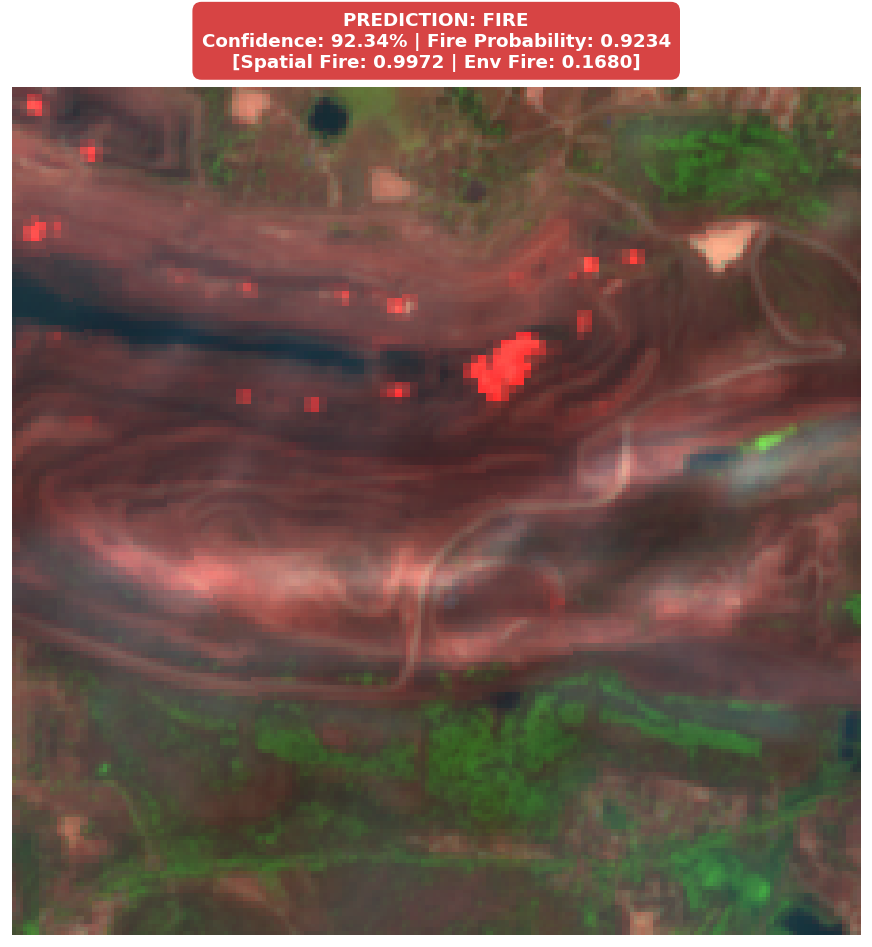

In [4]:
# -----------------------------------------------------------------------------
# 4. EXECUTION & VISUALIZATION
# -----------------------------------------------------------------------------
sample_weather = {
    "Temp": 32.5,
    "Humidity": 34.0,
    "Wind": 5.8,
    "Rainfall": 0.2,
    "Pressure": 94.2,
    "SolarRad": 7.8,
    "WindDir": 285.0,
    "DewPoint": 14.5,
    "Elevation": 450.0,
    "LandCover_ID": 10
}

sample_image_path = "/kaggle/input/datasets/grandvizard/sample/Picture1.png"

# Execute inference
result, satellite_image = predict_fire(sample_image_path, sample_weather)

# Configure plot styling based on detection outcome
# Configure plot styling based on detection outcome
is_fire = result["prediction"] == "FIRE"
badge_color = "#D32F2F" if is_fire else "#2E7D32"  # Red for fire, green for safe

fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.imshow(satellite_image)
ax.axis("off")

# Updated keys matching predict_fire dictionary output
title_text = (
    f"PREDICTION: {result['prediction']}\n"
    f"Confidence: {result['confidence']:.2%} | Fire Probability: {result['fire_probability']:.4f}\n"
    f"[Spatial Fire: {result['stream_probabilities']['spatial_stream_fire_prob']:.4f} | "
    f"Env Fire: {result['stream_probabilities']['environmental_stream_fire_prob']:.4f}]"
)

ax.set_title(
    title_text,
    fontsize=11,
    fontweight="bold",
    color="white",
    pad=12,
    bbox=dict(boxstyle="round,pad=0.5", facecolor=badge_color, edgecolor="none", alpha=0.9)
)

plt.tight_layout()
plt.show()

In [5]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# 1. INITIALIZE SHAP EXPLAINERS
# ==============================================================================
print("[XAI] Initializing Tree and Linear SHAP explainers...")

# TreeExplainer for Environmental LightGBM
explainer_env = shap.TreeExplainer(model_env)

# TreeExplainer for Spatial LightGBM (trained on 64 PCA features)
explainer_spatial = shap.TreeExplainer(model_spatial)

# LinearExplainer for Logistic Regression Meta-Gater
# A representative reference sample of stream probabilities
meta_background = np.array([
    [0.1, 0.1],
    [0.5, 0.5],
    [0.9, 0.9],
    [0.1, 0.8],
    [0.8, 0.1]
])
explainer_meta = shap.LinearExplainer(meta_gater, meta_background)


# ==============================================================================
# 2. LOCAL EXPLANATION FUNCTION
# ==============================================================================
def explain_prediction(image_path, env_dict, save_path=None):
    """
    Computes local SHAP attributions for:
      1. Environmental tabular features (direct log-odds).
      2. Top MobileNet feature channels (via PCA back-projection).
      3. Meta-Gater stream weights.
    """
    # Extract features using existing processors
    X_spatial_df, sat_img = fetch_spatial_embedding(image_path)
    X_env_df = build_environmental_features(env_dict)

    # Re-calculate individual stream probabilities (Class 1)
    p_sp_c1 = float(model_spatial.predict_proba(X_spatial_df)[:, 1][0])
    p_env_c1 = float(model_env.predict_proba(X_env_df)[:, 1][0])
    meta_input = np.column_stack([[p_env_c1], [p_sp_c1]])

    # 1. Compute environmental SHAP values
    shap_env = explainer_env(X_env_df)

    # 2. Compute spatial SHAP values and back-project to 1280 MobileNet features
    shap_spatial_64 = explainer_spatial(X_spatial_df)
    shap_spatial_1280 = np.dot(shap_spatial_64.values[0], pca.components_)

    # 3. Compute meta-gater SHAP values
    df_meta_input = pd.DataFrame(meta_input, columns=["Env_Stream_Prob", "Spatial_Stream_Prob"])
    shap_meta = explainer_meta(df_meta_input)

    # Visualization layout
    fig = plt.figure(figsize=(18, 10), dpi=120)
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.2])

    # Plot 1: Satellite Input Image
    ax_img = fig.add_subplot(gs[0, 0])
    ax_img.imshow(sat_img)
    ax_img.set_title("Input Satellite Patch", fontsize=11, fontweight="bold")
    ax_img.axis("off")

    # Plot 2: Meta-Gater Contributions
    ax_meta = fig.add_subplot(gs[0, 1])
    meta_vals = shap_meta.values[0]
    bars = ax_meta.barh(["Env Stream", "Spatial Stream"], meta_vals, color=["#1976D2", "#F57C00"])
    ax_meta.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax_meta.set_xlabel("SHAP Value (Impact on Meta Log-Odds)")
    ax_meta.set_title("Meta-Gater Stream Contributions", fontsize=11, fontweight="bold")
    for bar in bars:
        w = bar.get_width()
        offset = 0.01 if w >= 0 else -0.01
        ax_meta.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:+.3f}", va="center", fontsize=9)

    # Plot 3: Top 10 MobileNet Feature Channels
    ax_proj = fig.add_subplot(gs[0, 2])
    top_indices = np.argsort(np.abs(shap_spatial_1280))[-10:]
    ax_proj.barh([f"Channel_{i}" for i in top_indices], shap_spatial_1280[top_indices], color="#7B1FA2")
    ax_proj.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax_proj.set_xlabel("Back-projected Attribution")
    ax_proj.set_title("Top 10 MobileNet Latent Channels", fontsize=11, fontweight="bold")

    # Plot 4: Environmental Feature Attributions
    ax_env = fig.add_subplot(gs[1, :])
    env_series = pd.Series(shap_env.values[0], index=X_env_df.columns).sort_values()
    
    # Class 1 = NO_FIRE: Positive values lower fire risk, negative values increase fire risk
    bar_colors = ["#D32F2F" if val < 0 else "#2E7D32" for val in env_series.values]
    y_coords = np.arange(len(env_series))
    ax_env.barh(y_coords, env_series.values, color=bar_colors)
    ax_env.set_yticks(y_coords)
    ax_env.set_yticklabels(env_series.index, fontsize=10)
    ax_env.axvline(0, color="black", linestyle="-", linewidth=0.8)
    ax_env.set_xlabel("SHAP Value (Impact on Model Log-Odds for Class 1: NO_FIRE)", fontsize=10)
    ax_env.set_title(
        "Environmental Feature Contributions (Green = Lower Fire Risk, Red = Higher Fire Risk)",
        fontsize=11,
        fontweight="bold"
    )

    for idx, (val, col_name) in enumerate(zip(env_series.values, env_series.index)):
        raw_val = X_env_df[col_name].iloc[0]
        label = f" {val:+.3f} (Value: {raw_val:.2f})"
        align = "left" if val >= 0 else "right"
        ax_env.text(val, idx, label, va="center", ha=align, fontsize=9)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()


# ==============================================================================
# 3. GLOBAL TABULAR EXPLANATION FUNCTION
# ==============================================================================
def explain_global_environmental(X_env_array, feature_names):
    """
    Generates a SHAP Beeswarm summary plot across a batch of environmental samples.
    """
    print("[XAI] Generating Global Environmental SHAP Summary...")
    df_env_batch = pd.DataFrame(X_env_array, columns=feature_names)
    batch_shap_values = explainer_env(df_env_batch)

    plt.figure(figsize=(10, 6), dpi=120)
    shap.summary_plot(batch_shap_values, df_env_batch, show=False)
    plt.title("Global Environmental Feature Importance", fontsize=12, pad=12)
    plt.tight_layout()
    plt.show()

[XAI] Initializing Tree and Linear SHAP explainers...



[SPATIAL] Loading image from: /kaggle/input/datasets/grandvizard/sample/Picture1.png
[SPATIAL] Original Image Dimensions: 224x224
[SPATIAL] Resized image to 224x224 for MobileNetV2 input.
[SPATIAL] Extracting high-dimensional feature representations...
[SPATIAL] Raw embedding vector shape: (1, 1280) (1280-dim)
[SPATIAL] Applied PCA transformation -> Reduced to (1, 64) (64-dim)

[ENV] Assembling environmental features and meteorological indices...
[ENV] Raw metrics: Temp=32.50°C, RH=34.00%, Wind=5.80 m/s
[ENV] Computed VPD (Vapor Pressure Deficit) : 3.2278 kPa
[ENV] Computed HDW (Hot-Dry-Windy Index)    : 18.7213
[ENV] Processed feature vector shape: (1, 12) (12 features)


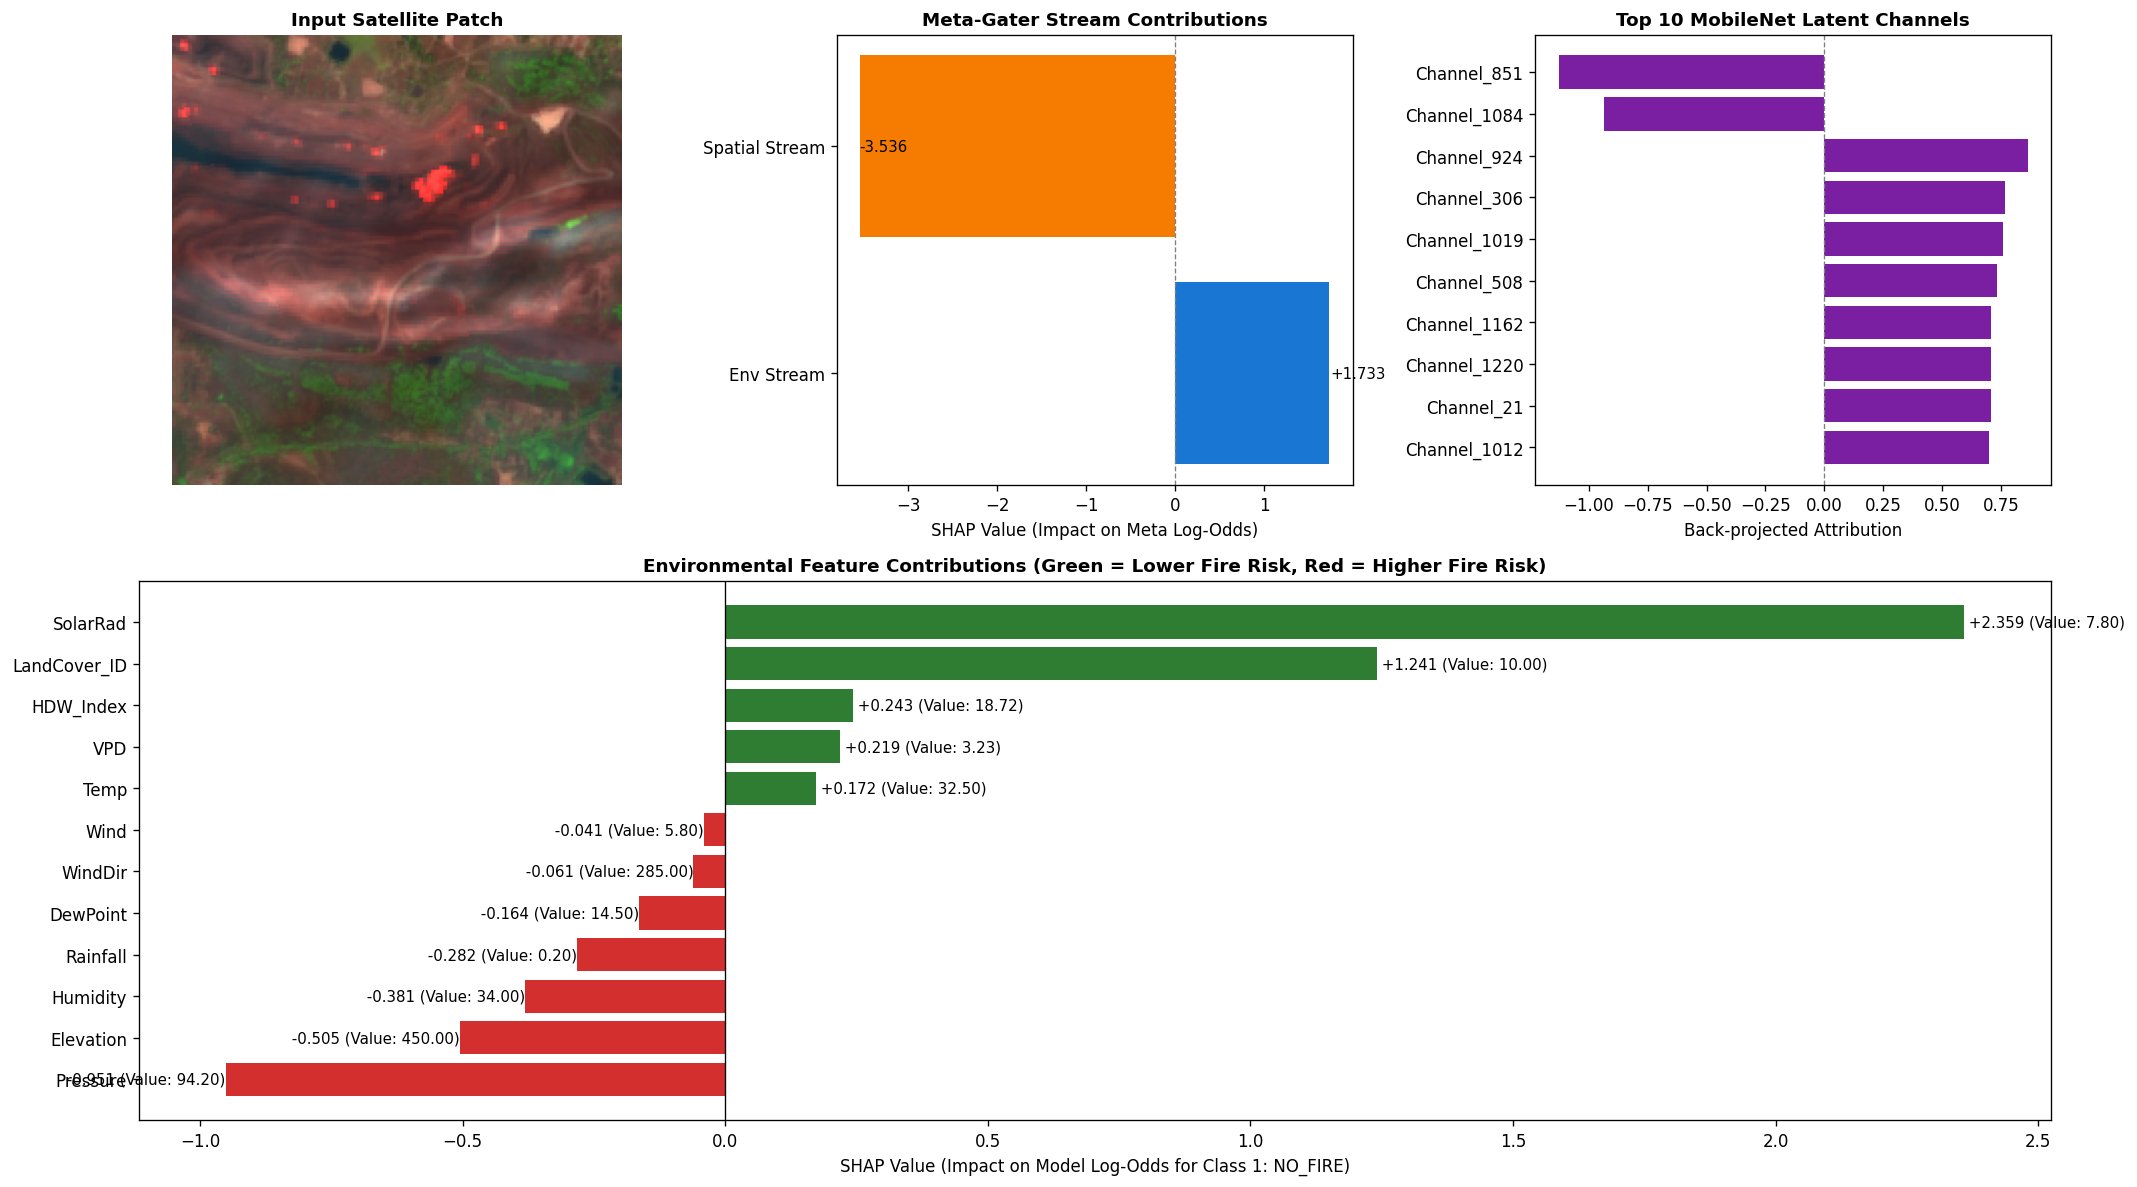

In [6]:
explain_prediction(sample_image_path, sample_weather)